<a href="https://colab.research.google.com/github/Meetra21/Curvature-Orientation-MLP/blob/main/Curvature_Orientation_pipeline_EMNIST_Letters_Updated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install dependencies
!pip install --quiet tensorflow tensorflow-datasets opencv-python tqdm scikit-learn

import cv2
import time
import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models, callbacks, regularizers
from tqdm import tqdm

# 1. Extract curvature and gradient orientation (unchanged)
def extract_curv_and_orientation(images):
    N = images.shape[0]
    curv_abs   = np.zeros((N,28,28), dtype=np.float32)
    curv_sign  = np.zeros((N,28,28), dtype=np.float32)
    orient_map = np.zeros((N,28,28), dtype=np.float32)
    for i, img in enumerate(tqdm(images, desc="Extracting features")):
        gx  = cv2.Sobel(img, cv2.CV_32F, 1, 0, ksize=3)
        gy  = cv2.Sobel(img, cv2.CV_32F, 0, 1, ksize=3)
        fxx = cv2.Sobel(img, cv2.CV_32F, 2, 0, ksize=3)
        fyy = cv2.Sobel(img, cv2.CV_32F, 0, 2, ksize=3)
        fxy = cv2.Sobel(img, cv2.CV_32F, 1, 1, ksize=3)
        num   = fxx * gy**2 - 2*fxy * gx * gy + fyy * gx**2
        denom = (gx**2 + gy**2 + 1e-8)**1.5
        k     = num / (denom + 1e-8)
        k_abs = np.abs(k)
        if k_abs.max() > 0:
            k_abs /= k_abs.max()
        curv_abs[i]  = k_abs
        curv_sign[i] = np.sign(k)
        theta = np.arctan2(gy, gx)
        orient_map[i] = (theta + np.pi) / (2*np.pi)
    return curv_abs, curv_sign, orient_map

# 2. Load & combine EMNIST Letters
(ds_train, ds_test), _ = tfds.load(
    'emnist/letters',
    split=['train','test'],
    as_supervised=True,
    with_info=True
)
imgs, lbls = [], []
for img, lbl in tfds.as_numpy(ds_train.concatenate(ds_test)):
    imgs.append(img.squeeze())
    lbls.append(int(lbl) - 1)
imgs = np.stack(imgs)
lbls = np.array(lbls)

# 3. Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    imgs, lbls, train_size=0.8,
    stratify=lbls, random_state=42
)

# 4. Compute features
curv_abs_tr, curv_sign_tr, orient_tr = extract_curv_and_orientation(X_train)
curv_abs_te,  curv_sign_te,  orient_te  = extract_curv_and_orientation(X_test)

# 5. Flatten & stack (3×784 = 2352 dims)
def stack_flatten(a, s, o):
    N = a.shape[0]
    return np.hstack([a.reshape(N,-1), s.reshape(N,-1), o.reshape(N,-1)])
X_train_feat = stack_flatten(curv_abs_tr, curv_sign_tr, orient_tr)
X_test_feat  = stack_flatten(curv_abs_te,  curv_sign_te,  orient_te)




Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

...

Shuffling /root/tensorflow_datasets/emnist/letters/incomplete.QV4Q8A_3.1.0/emnist-train.tfrecord*...:   0%|   …

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/letters/incomplete.QV4Q8A_3.1.0/emnist-test.tfrecord*...:   0%|    …

Dataset emnist downloaded and prepared to /root/tensorflow_datasets/emnist/letters/3.1.0. Subsequent calls will reuse this data.


Extracting features: 100%|██████████| 20720/20720 [00:04<00:00, 4740.11it/s]


In [ ]:
# 7. Build MLP model (input dim = 2352)
model = models.Sequential([
    layers.Input(shape=(2352,)),
    layers.Dense(2048), layers.BatchNormalization(), layers.Activation('relu'), layers.Dropout(0.5),
    layers.Dense(1024), layers.BatchNormalization(), layers.Activation('relu'), layers.Dropout(0.5),
    layers.Dense(512),  layers.BatchNormalization(), layers.Activation('relu'), layers.Dropout(0.4),
    layers.Dense(256),  layers.BatchNormalization(), layers.Activation('relu'), layers.Dropout(0.3),
    layers.Dense(26, activation='softmax')
])

# 8. Compile with a float learning rate so ReduceLROnPlateau can adjust it
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 9. Callbacks (patience=8, up to 100 epochs)
es  = callbacks.EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True, verbose=1)
rlr = callbacks.ReduceLROnPlateau(  monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6, verbose=1)

# 10. Train
t0 = time.time()
history = model.fit(
    X_train_feat, y_train,
    validation_split=0.1,
    epochs=100,
    batch_size=128,
    callbacks=[es, rlr],
    verbose=2
)
train_time = time.time() - t0

# 11. Evaluate & report
t1 = time.time()
loss, acc  = model.evaluate(X_test_feat, y_test, verbose=2)
infer_time = time.time() - t1

print(f"\nImproved Curvature+Orientation MLP on EMNIST Letters")
print(f"Test Accuracy   : {acc*100:.2f}%")
print(f"Training Time   : {train_time:.1f}s")
print(f"Inference Time  : {infer_time:.1f}s for {X_test_feat.shape[0]} samples")

Epoch 1/100
583/583 - 125s - 215ms/step - accuracy: 0.6049 - loss: 1.3098 - val_accuracy: 0.7705 - val_loss: 0.6994 - learning_rate: 1.0000e-03
Epoch 2/100
583/583 - 119s - 204ms/step - accuracy: 0.7747 - loss: 0.7074 - val_accuracy: 0.8313 - val_loss: 0.5009 - learning_rate: 1.0000e-03
Epoch 3/100
583/583 - 113s - 193ms/step - accuracy: 0.8185 - loss: 0.5596 - val_accuracy: 0.8527 - val_loss: 0.4494 - learning_rate: 1.0000e-03
Epoch 4/100
583/583 - 147s - 252ms/step - accuracy: 0.8436 - loss: 0.4770 - val_accuracy: 0.8579 - val_loss: 0.4260 - learning_rate: 1.0000e-03
Epoch 5/100
583/583 - 116s - 199ms/step - accuracy: 0.8626 - loss: 0.4145 - val_accuracy: 0.8653 - val_loss: 0.4092 - learning_rate: 1.0000e-03
Epoch 6/100
583/583 - 147s - 252ms/step - accuracy: 0.8751 - loss: 0.3724 - val_accuracy: 0.8711 - val_loss: 0.4057 - learning_rate: 1.0000e-03
Epoch 7/100
583/583 - 144s - 247ms/step - accuracy: 0.8870 - loss: 0.3297 - val_accuracy: 0.8766 - val_loss: 0.4049 - learning_rate: 1.0


Classification Report (Per-class and Aggregate):
              precision    recall  f1-score   support

           0     0.8231    0.8486    0.8357       839
           1     0.9176    0.9023    0.9099       839
           2     0.9319    0.9242    0.9280       844
           3     0.9032    0.9107    0.9069       840
           4     0.9272    0.9327    0.9300       847
           5     0.9329    0.8951    0.9136       839
           6     0.7950    0.7228    0.7572       837
           7     0.8759    0.8935    0.8846       845
           8     0.7145    0.7009    0.7076       846
           9     0.9091    0.9048    0.9069       840
          10     0.9413    0.9080    0.9244       848
          11     0.6943    0.7248    0.7092       843
          12     0.9404    0.9571    0.9487       840
          13     0.8715    0.8956    0.8834       833
          14     0.9026    0.9466    0.9241       842
          15     0.9406    0.9539    0.9472       846
          16     0.7970    0.80

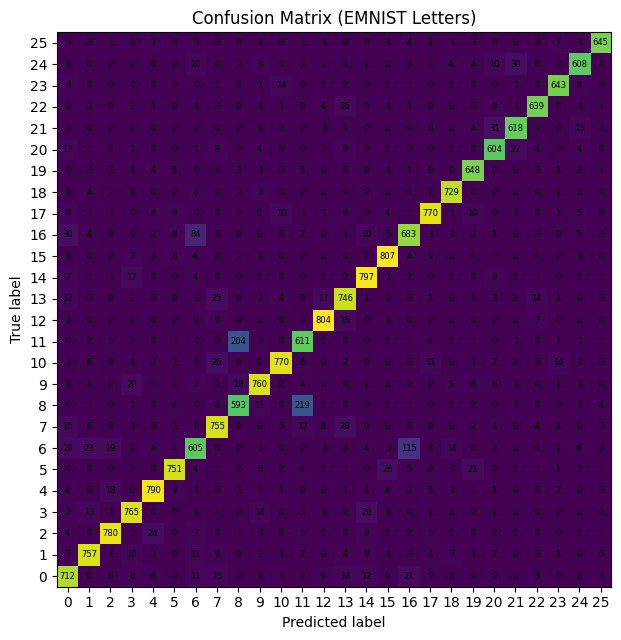

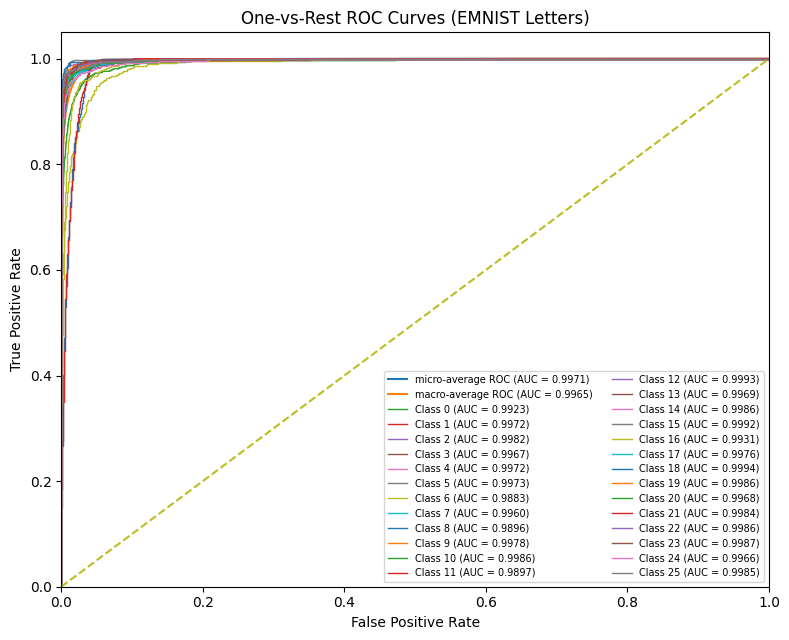

In [ ]:
# =========================
# 12. Detailed metrics & plots (append-only; works for EMNIST Letters/MNIST)
# =========================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report, precision_recall_fscore_support,
    roc_curve, auc, confusion_matrix
)
from sklearn.preprocessing import label_binarize

# ---- Predictions & probabilities ----
y_prob = model.predict(X_test_feat, verbose=0)           # (N, C) probabilities
y_pred = np.argmax(y_prob, axis=1)

# ---- Class set (robust for EMNIST Letters labels) ----
classes = np.array(sorted(np.unique(y_test)))            # e.g., 0..25
n_classes = len(classes)

print("\nClassification Report (Per-class and Aggregate):")
print(classification_report(y_test, y_pred, labels=classes, digits=4))

# Macro/Micro aggregates
prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(
    y_test, y_pred, labels=classes, average='macro'
)
prec_micro, rec_micro, f1_micro, _ = precision_recall_fscore_support(
    y_test, y_pred, labels=classes, average='micro'
)
print(f"Macro Avg -> Precision: {prec_macro:.4f}, Recall: {rec_macro:.4f}, F1: {f1_macro:.4f}")
print(f"Micro Avg -> Precision: {prec_micro:.4f}, Recall: {rec_micro:.4f}, F1: {f1_micro:.4f}")

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# ---- Confusion matrix (figure) ----
cm = confusion_matrix(y_test, y_pred, labels=classes)

plt.figure(figsize=(7.5, 6.5))
plt.imshow(cm, interpolation='nearest', origin='lower')  # <-- Flip vertically
plt.title('Confusion Matrix (EMNIST Letters)')
plt.xlabel('Predicted label')
plt.ylabel('True label')

# Axis labels
plt.xticks(range(n_classes), classes, rotation=0)
plt.yticks(range(n_classes), classes)

# Annotate cell values
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, str(cm[i, j]),
                 ha="center", va="center", fontsize=6)

plt.tight_layout()
plt.savefig("confusion_matrix_emnist_letters.png", dpi=150)
plt.show()


# ---- ROC curves (one-vs-rest) ----
# Binarize ground-truth using discovered class set
y_test_bin = label_binarize(y_test, classes=classes)     # shape: (N, C)

# Guard for edge case: if a class is missing in test split, skip its ROC
fpr, tpr, roc_auc = {}, {}, {}
valid_class_indices = []
for idx, c in enumerate(classes):
    if y_test_bin[:, idx].sum() > 0:                     # class appears in y_test
        fpr[c], tpr[c], _ = roc_curve(y_test_bin[:, idx], y_prob[:, idx])
        roc_auc[c] = auc(fpr[c], tpr[c])
        valid_class_indices.append(idx)

# Micro-average ROC
fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin[:, valid_class_indices].ravel(),
                                          y_prob[:, valid_class_indices].ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# Macro-average ROC (average the interpolated TPRs of valid classes)
all_fpr = np.unique(
    np.concatenate([fpr[c] for c in classes if c in fpr])
) if len(valid_class_indices) > 0 else np.array([0.0, 1.0])
mean_tpr = np.zeros_like(all_fpr)
count_valid = 0
for c in classes:
    if c in fpr:
        mean_tpr += np.interp(all_fpr, fpr[c], tpr[c])
        count_valid += 1
if count_valid > 0:
    mean_tpr /= count_valid
    fpr["macro"] = all_fpr
    tpr["macro"] = mean_tpr
    roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])
else:
    fpr["macro"] = np.array([0.0, 1.0])
    tpr["macro"] = np.array([0.0, 1.0])
    roc_auc["macro"] = 0.5

# ---- Plot ROC curves (micro + macro + per-class) ----
plt.figure(figsize=(8, 6.5))
plt.plot(fpr["micro"], tpr["micro"], label=f'micro-average ROC (AUC = {roc_auc["micro"]:.4f})')
plt.plot(fpr["macro"], tpr["macro"], label=f'macro-average ROC (AUC = {roc_auc["macro"]:.4f})')

# Per-class curves (may be dense for 26 classes; keep or comment out)
for c in classes:
    if c in fpr:
        plt.plot(fpr[c], tpr[c], lw=1, label=f'Class {c} (AUC = {roc_auc[c]:.4f})')

plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('One-vs-Rest ROC Curves (EMNIST Letters)')
plt.legend(loc="lower right", fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig("ROC_Curves_EMNIST_Letters.png", dpi=150)
plt.show()
